# Lab 12 — Transformers

**Name:** Ali Alhashim
**Student ID:** 2230004042

The task (exploring the layers and attention heads of `bert-base-uncased`) is answered at the end. The lab's own cells are kept unchanged above it.

# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Solution: Exploring Transformer Layers and Attention Heads

Load the pretrained `bert-base-uncased` model and its tokenizer. `attn_implementation="eager"` is needed so the model returns attention weights.

In [6]:
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

### 1. Number of Transformer layers and attention heads per layer

In [7]:
num_layers = bert_model.config.num_hidden_layers
num_heads = bert_model.config.num_attention_heads

print("Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)

Transformer layers: 12
Attention heads per layer: 12


### 2. Total number of attention heads across all layers

In [8]:
total_heads = num_layers * num_heads

print(f"Total attention heads = {num_layers} layers x {num_heads} heads = {total_heads}")

Total attention heads = 12 layers x 12 heads = 144


### 3. Attention weights from the 3rd layer, 2nd head

Python indexing starts at 0, so the **third layer** is `attentions[2]` and the **second head** is index `1`.

In [9]:
task_sentence = "Transformers use self-attention to understand language."

task_inputs = bert_tokenizer(task_sentence, return_tensors="pt")
task_tokens = bert_tokenizer.convert_ids_to_tokens(task_inputs["input_ids"][0])

with torch.no_grad():
    task_outputs = bert_model(**task_inputs, output_attentions=True)

# attentions is a tuple with one tensor per layer, each shaped (batch, heads, seq_len, seq_len)
print("Number of attention tensors (one per layer):", len(task_outputs.attentions))
print("Shape of one layer's attention:", task_outputs.attentions[0].shape)

layer_index = 2   # third layer
head_index = 1    # second head
layer3_head2 = task_outputs.attentions[layer_index][0, head_index]

print("\nTokens:", task_tokens)
print("Attention matrix shape:", layer3_head2.shape)
print("Attention weights (layer 3, head 2):\n", layer3_head2)
print("\nEach row sums to:", layer3_head2.sum(dim=-1))

Number of attention tensors (one per layer): 12
Shape of one layer's attention: torch.Size([1, 12, 11, 11])

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention matrix shape: torch.Size([11, 11])
Attention weights (layer 3, head 2):
 tensor([[7.3176e-01, 7.9132e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03,
         1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03,
         9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02,
         8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9671e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02,
         6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01, 6.9677e-02, 7.1289e-02, 6.3943e-01, 1.2104e-02, 1.2819e-02,
         3

,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159


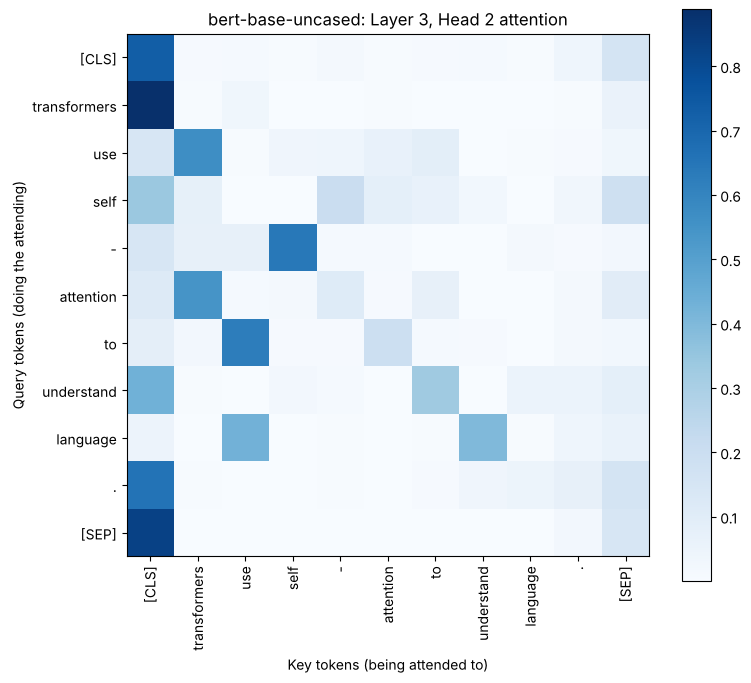

In [10]:
# Same matrix as a labelled table and a heatmap, so it's easy to read
import pandas as pd
import matplotlib.pyplot as plt

attention_table = pd.DataFrame(layer3_head2.numpy(), index=task_tokens, columns=task_tokens).round(3)
display(attention_table)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(layer3_head2.numpy(), cmap="Blues")
ax.set_xticks(range(len(task_tokens)))
ax.set_xticklabels(task_tokens, rotation=90)
ax.set_yticks(range(len(task_tokens)))
ax.set_yticklabels(task_tokens)
ax.set_xlabel("Key tokens (being attended to)")
ax.set_ylabel("Query tokens (doing the attending)")
ax.set_title("bert-base-uncased: Layer 3, Head 2 attention")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

### 4. What the rows and columns of the attention matrix represent

The attention matrix is a square **seq_len × seq_len** matrix, where seq_len is the number of tokens after tokenization (including `[CLS]`, `[SEP]` and any sub-word pieces).

- **Rows = query tokens.** Row *i* belongs to the token that is *doing the attending*: the token whose new, contextual representation is being built.
- **Columns = key tokens.** Column *j* belongs to the token that is *being attended to*: a token whose information may be pulled in.
- **Value at [i, j]** is the attention weight: how much token *i* focuses on token *j* in this layer and head. A higher value means token *j* contributes more to token *i*'s updated representation.
- **Each row sums to 1**, because the weights come from a softmax over all the tokens. So a row is a probability distribution showing how one token spreads its attention across the whole sentence.
- The matrix is **not symmetric**: how much token *i* attends to *j* is generally different from how much *j* attends to *i*.

Different layers and heads learn different patterns. Some heads focus on neighbouring words, some on the special tokens `[CLS]` / `[SEP]`, and others on grammatically related words.